In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
df = pd.read_csv("/Users/kamika/Desktop/ironhack/Labs/lab-eda-univariate/amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.
Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.


Part 2: Exploring Product Prices and Ratings Across Categories and Brands

Objective: Investigate how different product categories influence product prices.

Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.
Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.
Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?
Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

In [8]:
#Part 1
#Top sellers

crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab["proportion"] = crosstab[True] / (crosstab[True] + crosstab[False])
crosstab.sort_values("proportion", ascending=False).head(10)

isBestSeller,False,True,proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
"Billiard, Snooker & Pool",241,8,0.032129
Pet Supplies,9152,285,0.030200
Home Brewing & Wine Making,239,7,0.028455
Mirrors,243,7,0.028000


In [9]:
from scipy.stats import chi2_contingency

ct = pd.crosstab(df["category"], df["isBestSeller"])
result = chi2_contingency(ct)
print("Chi2:", round(result.statistic, 2))
print("p-value:", result.pvalue)

Chi2: 36540.2
p-value: 0.0


In [10]:
from scipy.stats.contingency import association

association(ct, method="cramer")

0.1222829439760564

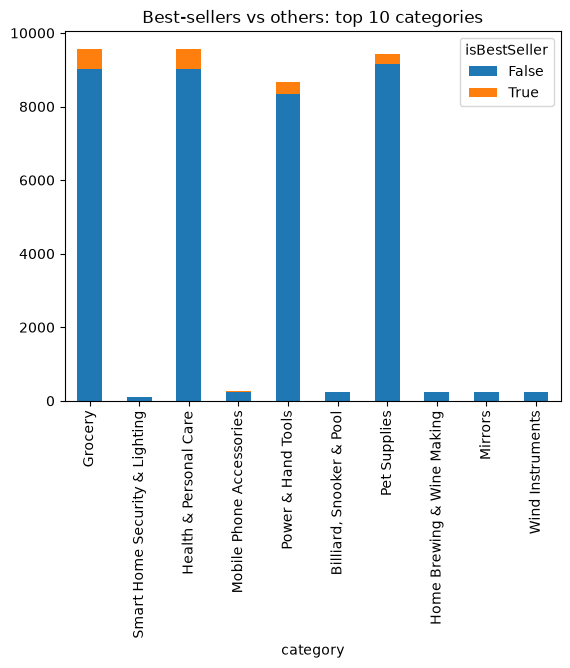

In [11]:
top10_bs = crosstab.sort_values("proportion", ascending=False).head(10).index

ct.loc[top10_bs].plot(kind="bar", stacked=True)
plt.title("Best-sellers vs others: top 10 categories")
plt.show()

In [12]:
#Part 2

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no_outliers = df[(df["price"] >= lower) & (df["price"] <= upper)]
print(df.shape, df_no_outliers.shape)

(2443651, 9) (2115963, 9)


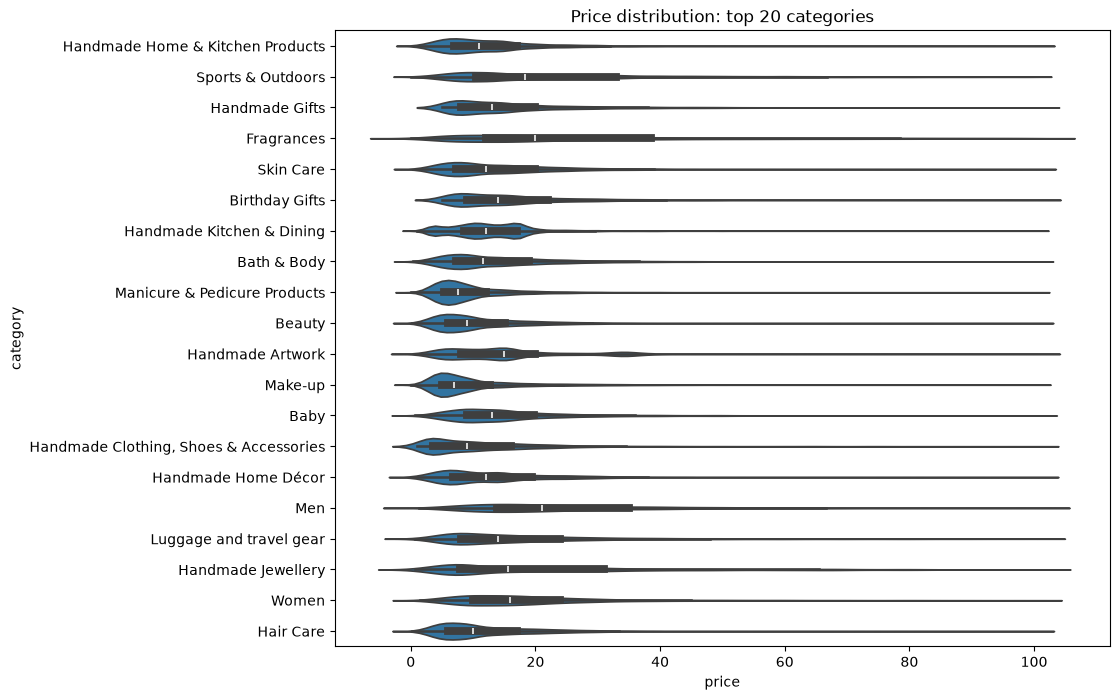

In [13]:
top20 = df_no_outliers["category"].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers["category"].isin(top20)]

plt.figure(figsize=(10, 8))
sns.violinplot(data=df_top20, x="price", y="category")
plt.title("Price distribution: top 20 categories")
plt.show()

In [14]:
df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False).head(5)

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

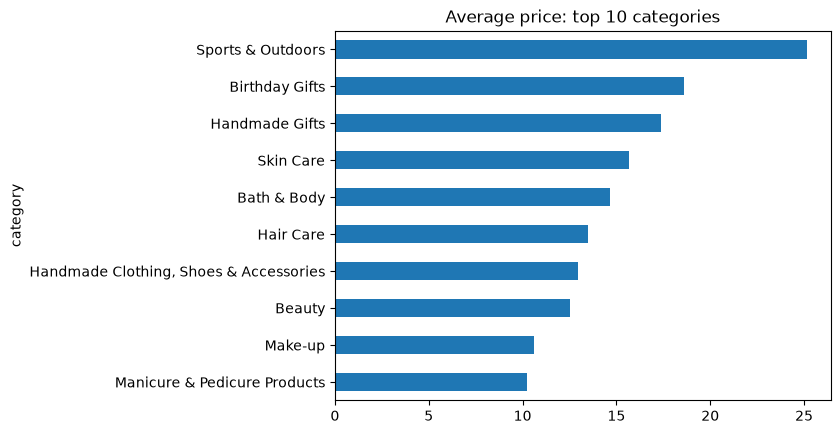

In [15]:
top10 = df_no_outliers["category"].value_counts().head(10).index

df_no_outliers[df_no_outliers["category"].isin(top10)].groupby("category")["price"].mean().sort_values().plot(kind="barh")
plt.title("Average price: top 10 categories")
plt.show()

In [16]:
df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False).head(5)

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

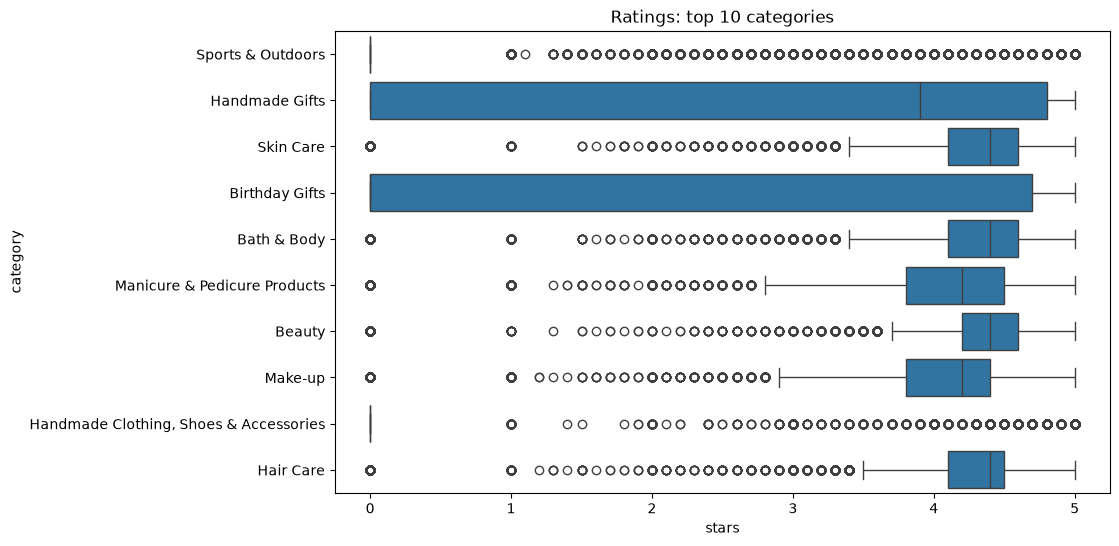

In [17]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_no_outliers[df_no_outliers["category"].isin(top10)], x="stars", y="category")
plt.title("Ratings: top 10 categories")
plt.show()

In [18]:
df_no_outliers.groupby("category")["stars"].median().sort_values(ascending=False).head(5)

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

In [19]:
#Part 3

In [20]:
from scipy.stats import pearsonr, spearmanr

pearson = pearsonr(df_no_outliers["price"], df_no_outliers["stars"])
spearman = spearmanr(df_no_outliers["price"], df_no_outliers["stars"])

print("Pearson r:", round(pearson.statistic, 3), "| p-value:", pearson.pvalue)
print("Spearman rho:", round(spearman.statistic, 3), "| p-value:", spearman.pvalue)

Pearson r: -0.078 | p-value: 0.0
Spearman rho: -0.067 | p-value: 0.0


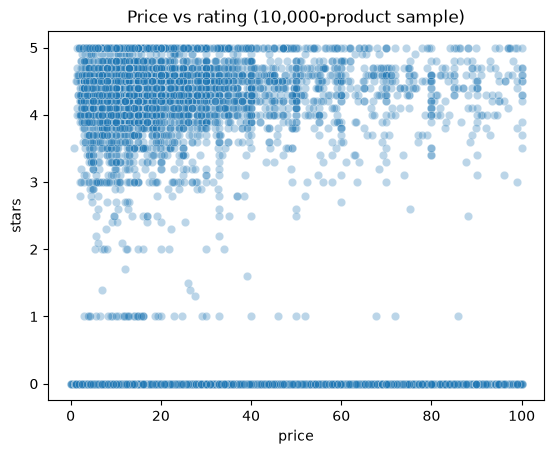

In [21]:
sample = df_no_outliers.sample(10000, random_state=42)

sns.scatterplot(data=sample, x="price", y="stars", alpha=0.3)
plt.title("Price vs rating (10,000-product sample)")
plt.show()

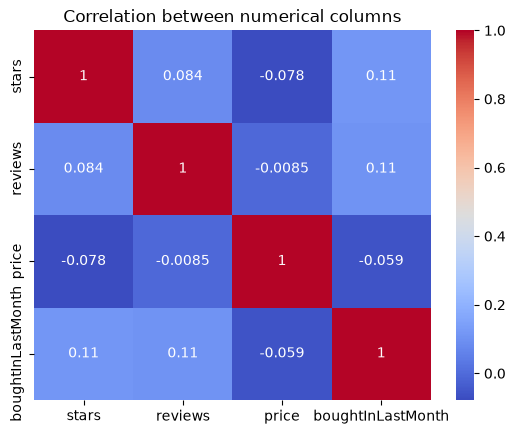

In [22]:
num_cols = ["stars", "reviews", "price", "boughtInLastMonth"]

sns.heatmap(df_no_outliers[num_cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation between numerical columns")
plt.show()

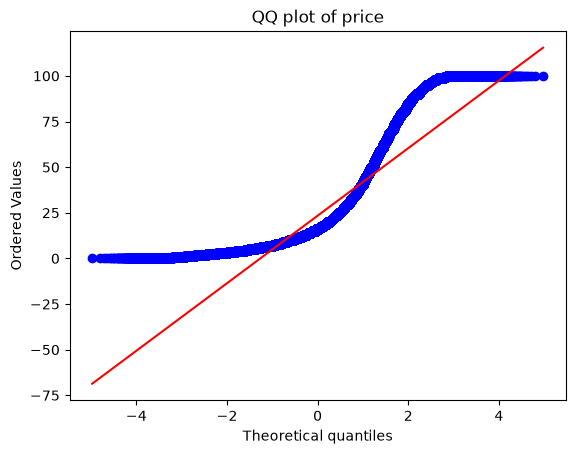

In [23]:
from scipy import stats

stats.probplot(df_no_outliers["price"], dist="norm", plot=plt)
plt.title("QQ plot of price")
plt.show()